NEU-DET Image Feature Analytics

This notebook extracts interpretable image features that will later feed classical ML and CNN comparisons.

Setup

The primary representation is grayscale because the NEU-DET images are visually grayscale.

In [2]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
ROOT = PROJECT / 'dataset' / 'NEU-DET'
OUTPUTS = PROJECT / 'outputs' / 'neu_feature_analytics'
OUTPUTS.mkdir(parents=True, exist_ok=True)
CLASSES = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

Intensity and Edge Features

These features describe brightness, contrast, and the amount of local edge structure.

In [3]:
def intensity_edges(gray):
    edges = cv2.Canny(gray, 80, 160)
    return {'gray_mean': gray.mean(), 'gray_std': gray.std(), 'gray_min': gray.min(), 'gray_max': gray.max(), 'edge_density': edges.mean() / 255, 'edge_mean': edges[edges > 0].mean() if np.any(edges) else 0}

LBP and Local Variance

LBP captures neighborhood texture patterns, while local variance measures surface roughness.

In [4]:
def texture_features(gray):
    center = gray[1:-1, 1:-1]
    neighbors = [gray[:-2, :-2], gray[:-2, 1:-1], gray[:-2, 2:], gray[1:-1, 2:], gray[2:, 2:], gray[2:, 1:-1], gray[2:, :-2], gray[1:-1, :-2]]
    lbp = sum((neighbor >= center).astype(np.uint8) << bit for bit, neighbor in enumerate(neighbors))
    local_mean = cv2.blur(gray.astype(np.float32), (15, 15))
    variance = cv2.blur((gray.astype(np.float32) - local_mean) ** 2, (15, 15))
    return {'lbp_mean': lbp.mean(), 'lbp_std': lbp.std(), 'local_variance_mean': variance.mean(), 'local_variance_std': variance.std()}

GLCM Features

A compact horizontal GLCM summarizes contrast, homogeneity, and energy of neighboring gray levels.

In [5]:
def glcm_features(gray):
    image = cv2.resize(gray, (100, 100), interpolation=cv2.INTER_AREA) // 16
    a, b = image[:, :-1].ravel(), image[:, 1:].ravel()
    matrix = np.zeros((16, 16), float)
    np.add.at(matrix, (a, b), 1)
    matrix = matrix + matrix.T
    matrix /= matrix.sum() if matrix.sum() else 1
    i, j = np.indices(matrix.shape)
    return {'glcm_contrast': np.sum((i - j) ** 2 * matrix), 'glcm_homogeneity': np.sum(matrix / (1 + abs(i - j))), 'glcm_energy': np.sum(matrix ** 2)}

DCT Features

DCT energy separates broad surface structure from fine texture and scratch-like detail.

In [6]:
def dct_features(gray):
    dct = cv2.dct(gray.astype(np.float32) / 255)  # DCT converts pixels into frequency coefficients.
    total = np.sum(dct ** 2)
    low = np.sum(dct[:32, :32] ** 2)  # The top-left block represents low-frequency energy.
    return {'dct_low_energy_ratio': low / total if total else 0, 'dct_high_energy_ratio': (total - low) / total if total else 0}

Morphological Features

Morphology converts a thresholded response into simple region measurements; it is treated as supporting evidence.

In [7]:
def morphology_features(gray):
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel)
    count, _, stats, _ = cv2.connectedComponentsWithStats(cleaned)
    areas = stats[1:, cv2.CC_STAT_AREA] if count > 1 else np.array([0])
    return {'morphology_region_count': len(areas), 'morphology_largest_area': areas.max(), 'morphology_foreground_ratio': np.mean(cleaned > 0)}

Feature Table

Each image is represented by one row of numerical features for later ML experiments.

In [ ]:
def extract(file, split, category):
    gray = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)
    row = {'split': split, 'category': category, 'file': file.name}
    row.update(intensity_edges(gray))
    row.update(texture_features(gray))
    row.update(glcm_features(gray))
    row.update(dct_features(gray))
    row.update(morphology_features(gray))
    return row

rows = []
for split in ['train', 'validation']:
    for category in CLASSES:
        for file in sorted((ROOT / split / 'images' / category).glob('*')):
            rows.append(extract(file, split, category))
features = pd.DataFrame(rows)
display(features.head(10))
features.to_csv(OUTPUTS / 'neu_feature_table.csv', index=False)
print('Rows:', len(features))

,split,category,file,gray_mean,gray_std,gray_min,gray_max,edge_density,edge_mean,lbp_mean,...,local_variance_mean,local_variance_std,glcm_contrast,glcm_homogeneity,glcm_energy,dct_low_energy_ratio,dct_high_energy_ratio,morphology_region_count,morphology_largest_area,morphology_foreground_ratio
0,train,crazing,crazing_1.jpg,160.636500,28.498493,60,255,0.352925,255.0,131.453729,...,428.986237,133.974289,1.343535,0.643207,0.045355,0.987880,0.012120,59,11720,0.424400
1,train,crazing,crazing_10.jpg,136.991575,35.717356,24,255,0.300425,255.0,132.171896,...,320.144653,134.454712,1.067475,0.678471,0.037901,0.988300,0.011700,37,19086,0.497900
2,train,crazing,crazing_100.jpg,138.498700,27.890065,41,255,0.321950,255.0,131.315019,...,345.592163,124.383034,1.225354,0.658468,0.047277,0.987011,0.012989,65,9664,0.361050
3,train,crazing,crazing_101.jpg,151.461850,24.196086,41,255,0.348850,255.0,130.460234,...,377.023285,104.994324,1.329091,0.643655,0.056347,0.987750,0.012250,62,11269,0.396425
4,train,crazing,crazing_102.jpg,97.017575,39.458047,13,255,0.172625,255.0,135.427150,...,184.899155,132.198013,0.746970,0.737552,0.046239,0.987345,0.012655,14,24436,0.615800


Rows: 1800


Feature Comparisons

Class summaries and boxplots identify features that may separate the six defect categories.

gray_mean         gray_std         gray_min         gray_max  \
                     mean     std     mean     std     mean     std     mean   
category                                                                       
crazing           141.107  28.669   29.054   4.836   36.470  17.460  247.147   
inclusion         106.366  33.874   13.020   5.479   69.507  24.415  144.903   
patches           132.511  43.065   54.220  12.308    9.650  10.522  244.673   
pitted_surface    176.666  49.347   26.675   7.674   99.580  39.131  233.470   
rolled-in_scale   117.913  24.624   16.090   3.473   52.080  14.901  190.833   
scratches          95.146  29.088   21.703   8.296   58.327  22.920  229.277   

                        edge_density         ... dct_low_energy_ratio         \
                    std         mean    std  ...                 mean    std   
category                                     ...                               
crazing          18.325        0.312  0.065  ...                0.987  0.001   
inclusion        40.106        0.001  0.002  ...                0.999  0.000   
patches          29.148        0.229  0.077  ...                0.989  0.004   
pitted_surface   37.771        0.083  0.089  ...                0.998  0.001   
rolled-in_scale  37.649        0.048  0.035  ...                0.995  0.001   
scratches        40.326        0.023  0.014  ...                0.994  0.004   

                dct_high_energy_ratio        morphology_region_count          \
                                 mean    std                    mean     std   
category                                                                       
crazing                         0.013  0.001                  53.320  18.472   
inclusion                       0.001  0.000                  11.693   8.123   
patches                         0.011  0.004                  12.177   8.817   
pitted_surface                  0.002  0.001                  31.007  27.897   
rolled-in_scale                 0.005  0.001                  36.467  13.381   
scratches                       0.006  0.004                   4.697   4.949   

                morphology_largest_area           morphology_foreground_ratio  \
                                   mean       std                        mean   
category                                                                        
crazing                       12651.467  5272.076                       0.445   
inclusion                     18591.143  4979.564                       0.500   
patches                       15578.183  6962.276                       0.464   
pitted_surface                15397.093  6132.536                       0.419   
rolled-in_scale               13342.777  4781.862                       0.448   
scratches                     27961.450  8062.364                       0.800   

                        
                   std  
category                
crazing          0.062  
inclusion        0.100  
patches          0.145  
pitted_surface   0.130  
rolled-in_scale  0.074  
scratches        0.172  

[6 rows x 36 columns]

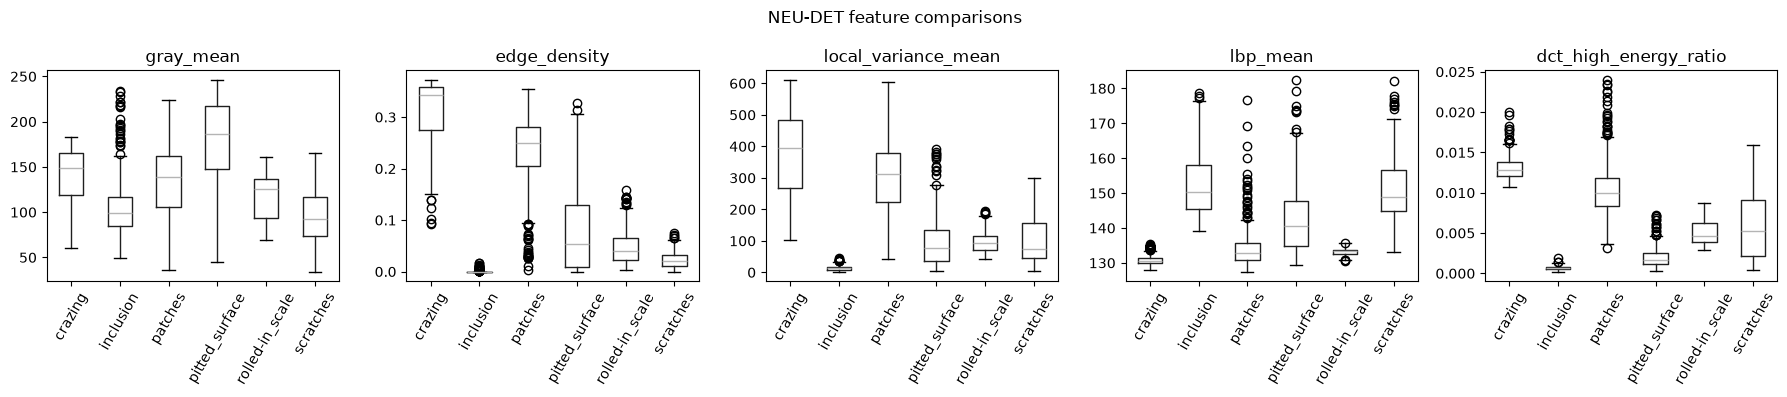

In [9]:
feature_names = [column for column in features.columns if column not in ['split', 'category', 'file']]
summary = features.groupby('category')[feature_names].agg(['mean', 'std']).round(3)
display(summary)
plot_names = ['gray_mean', 'edge_density', 'local_variance_mean', 'lbp_mean', 'dct_high_energy_ratio']
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for axis, name in zip(axes, plot_names):
    features.boxplot(column=name, by='category', ax=axis, grid=False)
    axis.set_title(name)
    axis.set_xlabel('')
    axis.tick_params(axis='x', rotation=60)
plt.suptitle('NEU-DET feature comparisons')
plt.tight_layout()
plt.savefig(OUTPUTS / 'feature_comparisons.png', bbox_inches='tight')
plt.show()

Initial Findings

These findings select candidate inputs for the classical ML and CNN notebooks.

In [10]:
print('Grayscale intensity, edges, texture, and DCT are the primary feature groups.')
print('LBP, GLCM, and local variance describe surface texture at different levels.')
print('Morphological measurements are supporting features because threshold responses can be noisy.')
print('The exported feature table will be used by the classical ML baseline.')

Grayscale intensity, edges, texture, and DCT are the primary feature groups.
LBP, GLCM, and local variance describe surface texture at different levels.
Morphological measurements are supporting features because threshold responses can be noisy.
The exported feature table will be used by the classical ML baseline.
